Version A (original/baseline) — BiLSTM from scratch: `embedding_dim=128, lstm_units=128, dropout=0.3, learning_rate=1e-3`. No hyperparameter changes from the default config.

In [1]:
%pip install tensorflow
%pip install scikit-learn pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import callbacks, layers, models
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

SEED = 42
tf.keras.utils.set_random_seed(SEED)

In [3]:
SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

with open(ARTIFACTS_DIR / "class_weights.json") as f:
    class_weights_raw = json.load(f)
class_weights = {int(k): v for k, v in class_weights_raw.items()}

LABEL_ORDER = list(label_encoder.classes_)
NUM_CLASSES = len(LABEL_ORDER)

# Reuse the encoder fit in ModelPrep.ipynb - never refit here, or the integer label IDs could drift out of sync with the BERT track's encoding.
y_train = label_encoder.transform(train_df["category"])
y_val = label_encoder.transform(val_df["category"])
y_test = label_encoder.transform(test_df["category"])

print("Train/val/test sizes:", len(train_df), len(val_df), len(test_df))
print("Classes:", LABEL_ORDER)

Train/val/test sizes: 224828 48178 48178
Classes: ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']


In [4]:
VOCAB_SIZE = 20000

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["text"])  # fit on TRAIN ONLY - val/test must not leak into the vocab

train_token_counts = train_df["text"].fillna("").astype(str).str.split().str.len()
p95 = int(np.percentile(train_token_counts, 95))
MAX_LEN = int(np.clip(p95, 20, 200))
print(f"95th percentile train token count: {p95}, MAX_LEN clamped to: {MAX_LEN}")


def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")


X_train = to_padded(train_df["text"])
X_val = to_padded(val_df["text"])
X_test = to_padded(test_df["text"])

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

95th percentile train token count: 561, MAX_LEN clamped to: 200


X_train shape: (224828, 200)
X_val shape: (48178, 200)
X_test shape: (48178, 200)


In [5]:
EMBEDDING_DIM = 128
LSTM_UNITS = 128
DROPOUT = 0.3

RECURRENT_DROPOUT = 0.0

model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True), #skip the 0 token both ways
    layers.Bidirectional(
        layers.LSTM(LSTM_UNITS, dropout=DROPOUT, recurrent_dropout=RECURRENT_DROPOUT, return_sequences=False)
    ),
    layers.Dropout(DROPOUT),
    layers.Dense(64, activation="relu"),
    layers.Dropout(DROPOUT),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,840,136 (10.83 MB)

 Trainable params: 2,840,136 (10.83 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
LEARNING_RATE = 1e-3

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [7]:
MODELS_DIR = Path("../../weights/lstm")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 64

EPOCHS = 15

callback_list = [
    callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    callbacks.ModelCheckpoint(
        filepath=str(MODELS_DIR / "lstm_model.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

USE_CLASS_WEIGHTS = False
fit_class_weight = class_weights if USE_CLASS_WEIGHTS else None

In [8]:
start_time = time.time()
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=fit_class_weight,
    callbacks=callback_list,
    verbose=2,
)
train_time_sec = time.time() - start_time
print(f"Training took {train_time_sec:.1f}s over {len(history.history['loss'])} epochs")

Epoch 1/15


3513/3513 - 7025s - 2s/step - accuracy: 0.7693 - loss: 0.7228 - val_accuracy: 0.8277 - val_loss: 0.5347


Epoch 2/15


3513/3513 - 1324s - 377ms/step - accuracy: 0.8461 - loss: 0.4908 - val_accuracy: 0.8367 - val_loss: 0.5123


Epoch 3/15


3513/3513 - 1457s - 415ms/step - accuracy: 0.8703 - loss: 0.4076 - val_accuracy: 0.8367 - val_loss: 0.5282


Epoch 4/15


3513/3513 - 1437s - 409ms/step - accuracy: 0.8898 - loss: 0.3418 - val_accuracy: 0.8390 - val_loss: 0.5597


Epoch 5/15


3513/3513 - 1463s - 416ms/step - accuracy: 0.9074 - loss: 0.2827 - val_accuracy: 0.8356 - val_loss: 0.6307


Training took 12705.9s over 5 epochs


In [9]:
model = tf.keras.models.load_model(MODELS_DIR / "lstm_model.keras")

In [10]:
inf_start = time.time()
y_pred_probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
inf_time_sec = time.time() - inf_start
y_pred = np.argmax(y_pred_probs, axis=1)

report_dict = classification_report(
    y_test, y_pred, target_names=LABEL_ORDER, output_dict=True, zero_division=0
)
report_text = classification_report(y_test, y_pred, target_names=LABEL_ORDER, zero_division=0)
print(report_text)

cm = confusion_matrix(y_test, y_pred)
test_accuracy = report_dict["accuracy"]
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(test_df) * 1000:.3f} ms/sample")

               precision    recall  f1-score   support

     Business       0.78      0.81      0.80      6323
Entertainment       0.86      0.88      0.87     12064
       Health       0.78      0.76      0.77      4197
     Politics       0.81      0.81      0.81      6238
      Science       0.71      0.55      0.62      1609
       Sports       0.91      0.94      0.93      5854
   Technology       0.79      0.86      0.82      5827
        World       0.90      0.79      0.84      6066

     accuracy                           0.83     48178
    macro avg       0.82      0.80      0.81     48178
 weighted avg       0.83      0.83      0.83     48178

Test accuracy: 0.8333
Inference time: 34.03s total, 0.706 ms/sample


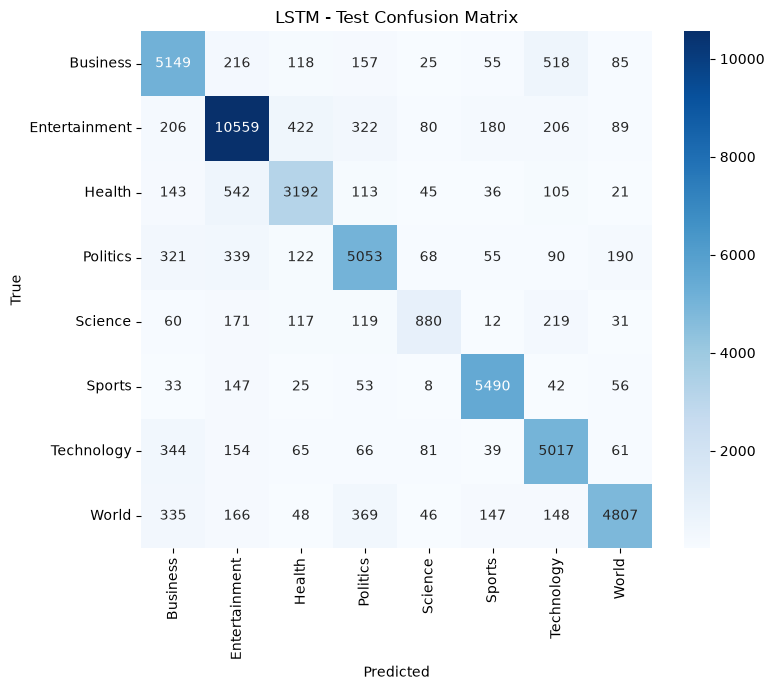

In [11]:
RESULTS_DIR = Path("../../../results/lstm")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("LSTM - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "LSTM_a_confusion_matrix.png", dpi=150)
plt.show()

In [12]:
with open(MODELS_DIR / "tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

config = {
    "max_len": MAX_LEN,
    "vocab_size": VOCAB_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "lstm_units": LSTM_UNITS,
    "batch_size": BATCH_SIZE,
    "epochs_planned": EPOCHS,
    "use_class_weights": USE_CLASS_WEIGHTS,
}
with open(MODELS_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

metrics = {
    "model_family": "lstm",
    "model_name": "bilstm-scratch-embed",
    "run_timestamp": pd.Timestamp.utcnow().isoformat(),
    "label_order": LABEL_ORDER,
    "config": {
        **config,
        "epochs_trained": len(history.history["loss"]),
        "learning_rate": LEARNING_RATE,
    },
    "train": {
        "n_train": len(train_df),
        "n_val": len(val_df),
        "train_time_sec": train_time_sec,
        "epochs_trained": len(history.history["loss"]),
        "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
    },
    "test": {
        "n_test": len(test_df),
        "accuracy": float(test_accuracy),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class": {
            cls: {
                "precision": float(report_dict[cls]["precision"]),
                "recall": float(report_dict[cls]["recall"]),
                "f1": float(report_dict[cls]["f1-score"]),
                "support": int(report_dict[cls]["support"]),
            }
            for cls in LABEL_ORDER
        },
        "confusion_matrix": cm.tolist(),
        "inference_time_sec_total": inf_time_sec,
        "inference_time_ms_per_sample": inf_time_sec / len(test_df) * 1000,
    },
    "environment": {
        "framework": "tensorflow",
        "framework_version": tf.__version__,
        "device": "GPU" if tf.config.list_physical_devices("GPU") else "CPU",
        "seed": SEED,
    },
}

with open(RESULTS_DIR / "LSTM_a_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved:")
print(" ", MODELS_DIR / "lstm_model.keras")
print(" ", MODELS_DIR / "tokenizer.pkl")
print(" ", MODELS_DIR / "config.json")
print(" ", RESULTS_DIR / "LSTM_a_metrics.json")

Saved:
  ..\..\weights\lstm\lstm_model.keras
  ..\..\weights\lstm\tokenizer.pkl
  ..\..\weights\lstm\config.json
  ..\..\..\results\lstm\LSTM_a_metrics.json


C:\Users\oofuc\AppData\Local\Temp\ipykernel_536\3706351312.py:19: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  "run_timestamp": pd.Timestamp.utcnow().isoformat(),
